<a href="https://colab.research.google.com/github/yuvasrisugu2008-maker/ITA0515--COMPUTER-VISION/blob/main/exp%2036.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Saving flower.jpg to flower (12).jpg


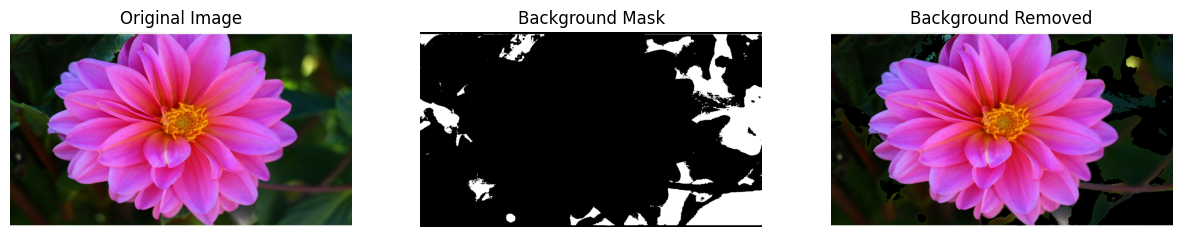

Background subtraction completed!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [48]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

def background_subtraction():

    # Upload image
    uploaded = files.upload()
    filename = next(iter(uploaded))

    # Read image
    image = cv2.imread(filename)

    if image is None:
        raise ValueError("Unable to read image.")

    # Convert BGR image to HSV
    hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)

    # Define background color range
    # Example: Green background
    lower = np.array([35, 40, 40])
    upper = np.array([85, 255, 255])

    # Detect background color
    mask = cv2.inRange(hsv, lower, upper)

    # Invert mask to remove background
    foreground_mask = cv2.bitwise_not(mask)

    # Remove background
    result = cv2.bitwise_and(
        image, image, mask=foreground_mask
    )

    # Display results
    plt.figure(figsize=(15, 5))

    plt.subplot(1, 3, 1)
    plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    plt.title("Original Image")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(mask, cmap="gray")
    plt.title("Background Mask")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
    plt.title("Background Removed")
    plt.axis("off")

    plt.show()

    # Save result
    cv2.imwrite("background_removed.jpg", result)

    print("Background subtraction completed!")

    files.download("background_removed.jpg")

background_subtraction()
